[![Open In Colab](https://colab.research.google.com/assets/colab-badge.svg)](https://colab.research.google.com/github/kulinskij-tech/QuantumMechanics2/blob/main/QM_py/qm2_nonstacpertheor_zad.ipynb)


In [2]:
import numpy as np
import matplotlib.pyplot as plt
import sympy
from sympy import *

# Нестаціонарна теорія збурень. Задачі.

$\newcommand{\ket}[1]{\left.\left\vert\, #1\,\right. \right \rangle}$
$\newcommand{\bra}[1]{\left. \langle \, #1\, \right\vert}$
$\newcommand{\braket}[2]{\langle \,#1 \vert #2 \, \rangle}$
$\newcommand{\av}[3]{\left\langle \,#1 \left \vert\, #2 \,\right\vert #3 \,\right \rangle}$

1. Обчисліть еволюцію дворівневої системи під дією сталого збурення яке вмикається в момент часу  t=0 . До моменту дії збурення система перебувала у збудженому стані. Як ймовірність спостереження системи у  початковому стані змінюється із часом?

1. За допомогою теорії збурень проаналізувати вплив періодичного збурення $\hat{V}(t) = \hat{V}\,\cos{\omega\,t}$, яке вмикається у момент часу $t=0$, на дворівневу систему $\ket{E_0}, \ket{E_1}$. Рівняння спростити і розв'язати у наближенні $\omega \approx (E_1 - E_0)/\hbar$.

1. Дослідіть залежність кута, що відповідає максимальній ймовірності вильоту фотоелектрона ( індикатриса спрямованості), від енергії фотона.

### Застосування золотого правила Фермі для обчислення фотоефекту.
Розглянемо іонізацію атома під дією монохроматичної ЕМХ. Оскільки напруженість поля у ЕМХ значно менша за напруженість внутрішньоатомного поля з класичної точки зору такий процес малоймовірний. Але з квантової т.з. такий процес буде відбуватись якщо енергія (частота) падаючої хвилі буде більше ніж потенціал іонізації. Таким чином більш суттєвим чинником є частота, яка за квантовою теорією визначає енергію фотона. 
Явище фотоефекту можна уявляти як перехід із стану дискретного у стан неперервного спектра під дією монохроматичного ЕМП з частотою $\omega$. 
Ймовірність таких переходів у одиницю часу згідно з <a id='fermigoldenrule'>__"золотим правилом Фермі"__ </a>:

$$\Pi_{i \to f} = \frac{2\pi}{\hbar}\int |V_{i,f}|^2\,\delta(E_{i}+\hbar\,\omega - E_f)\,\rho(E_f)\,df $$

$$E_{i}+\hbar\,\omega = E_{f}$$

де $f$ - сукупність квантових чисел кінцевого стану. В даному випадку електрон переходить із зв'язаного стану $\ket{0}$ з енергією $-I_{0}$ ($I_0$ - потенціал іонізації, для водню $I_0\approx 13.6\, eV$) у стан неперервного спектра $\ket{\mathbf{p}}$, який можна представляти як плоску хвилю з імпульсом $\mathbf{p}$, величина якого визначається законом збереження енергії. Оператор взаємодії атома з ЕПМ має вигляд:

$$\hat{V} = -\frac{q}{m}\mathbf{A}\cdot \mathbf{p} \to \frac{e}{m\,c}\,A_{x}(z)\,\hat{p}_{x}$$

Припустимо, що ЕМХ з лінійною x-поляризацією розповсюджується вздовж $z$:

$$A_{x} = A_0\,\cos\left(k\,z - \omega\,t\right)\,,\,\,\,\, A_0 = c\,\frac{\mathcal{E}_0}{\omega} $$

[Застосовуючи результат теорії збурень для частоти переходів отримаємо](https://colab.research.google.com/github/kulinskij-tech/QuantumMechanics2/blob/main/QM_py/qm2_nonstacpertheor.ipynb#eq_harmpert):
<!--  -->
$$\Pi_{0\to f} = \frac{2\pi}{\hbar}\,\left|\av{\mathbf{p}}{V}{0}\right|^2\,\rho(E_{\mathbf{p}})\,,\\
E_{\mathbf{p}} = \frac{\mathbf{p}^2}{2\,m} = \hbar\,\omega-I_{0}$$
<!--  -->
де
<!--  -->
$$\ket{0}\to \frac{1}{\sqrt{\pi}}\,e^{-r}\,,\quad \ket{\mathbf{p}}\to \frac{1}{\sqrt{V}}\, e^{i\,\frac{\mathbf{p}\,\mathbf{r}}{\hbar}}$$
<!--  -->
-вектори початкового та кінцевого станів електрона. Густина станів вільного електрона:

$$\rho(E_{\mathbf{p}}) = \frac{d\,N}{d\,E_{\mathbf{p}}} = 2\,V\frac{p^2\,dp\,d\Omega}{(2\pi\hbar)^3\,p/m\,dp}= 2\, V\frac{m\,p\,d\Omega}{(2\pi\hbar)^3}$$

Множник 2,  враховує виродження за проекцією спіна. Обчислимо відповідний матричний елемент:

In [3]:
x,r=symbols('x,r')
q=Symbol('q',positive=True)
xint=2*pi*integrate(cos(q*r*x),(x,-1,1))
integrate(xint*exp(-r)*r**2,(r,0,+oo))

8*pi/(q**4 + 2*q**2 + 1)


$$\av{0}{V}{\mathbf{p}} =\frac{e}{m\,c\,\sqrt{\pi}} A_0\,p_x\,\int e^{-r+i\,\mathbf{q}\mathbf{r}}\,d\mathbf{r} = \frac{8\,\sqrt{\pi} \, e}{m\,c} A_0\,p_x\,\frac{1}{\left(1+q^2\right)^2} $$

де

$$\mathbf{q} = \frac{\mathbf{p}}{\hbar} - \mathbf{k}$$

-хвильовий вектор передачі імпульсу (ми використовуємо безрозмірні масштаби у одиницях $a_B = m\,e^4/\hbar^2$) . Маємо:

\begin{equation}\label{eq_pi}
\Pi_{0\to f} = \frac{16\,e^2}{m\,c^2} A^2_0\,p^3\,\frac{\sin^2{\theta}\,\cos^2{\varphi}}{(1+q^2)^4}\,d\Omega
\end{equation}

Покладаючи $E_{\mathbf{p}}\ll \hbar\,\omega \sim I_{0}$, з \eqref{eq_pi} побудуємо діаграму спрямованості (див. Рис.). У граничному випадку $p\to 0$ максимум ймовірності відповідає напрямку 
дії електричної складової сили $e\,\mathcal{E}_0$. Вона відображає зростання передачі імпульсу у напрямку падаючої хвилі, що демонструє корпускулярно-хвильовий дуалізм ЕМХ при зміні частоти.

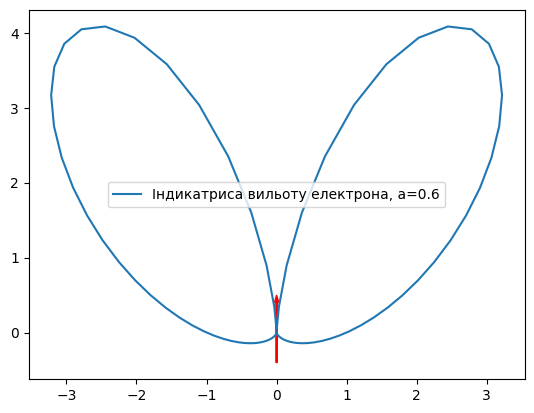

In [9]:
fig = plt.figure()
ax = fig.add_subplot(111) 
# Prepare arrays x, y, z
theta = np.linspace(- np.pi,  np.pi, 100)
a=0.6
r = np.sin(theta)**2/(1-a*np.cos(theta))**4
x = r * np.sin(theta)
z = r * np.cos(theta)
ax.arrow(0,-0.4, 0, 0.8,width = 0.02,head_length = 0.1,color='r')
ax.plot(x, z, label='Індикатриса вильоту електрона, a='+str(a))
ax.legend()
# ax.set(xlim=[-1/(1-a),1/(1-a)],ylim=[-1,1/(1-a)**2])
plt.show()